# Session 21: Assignment 2 Prep

Prep for CS156 Assignment 2. Assignment 2 extends the Assignment 1 pipeline (Food-Photo
Allergen Detector) with a model/technique from Unit 2. Selected extension: **convolutional
autoencoder**, trained unsupervised on the same 199 food photos, to see whether reconstruction
error says anything useful, specifically whether it flags the same confound/mislabel-prone
photos that Grad-CAM already surfaced in Assignment 1.

- Question 1 (two-slide presentation): see `presentation.pdf` in this folder.
- Core Question (this notebook): tools/datasets research, then re-implementation.
- Extension Question: see `unit2_answer_key.md` (bonus: full Unit 2 answer key).


## Core Question 3a-b: Tools and Datasets

**a. What tools are available?**
- `tf.keras` (`Conv2D`/`Conv2DTranspose`) — the standard route, used below.
- PyTorch (`nn.Conv2d`/`nn.ConvTranspose2d`) — equivalent, not used here since the rest of this
  repo's pipeline (Assignment 1, Sessions 17-20) is already Keras-based.
- The Keras blog post *Building Autoencoders in Keras* (francoiskeras.io/blog) and the
  TensorFlow tutorial *Intro to Autoencoders* (tensorflow.org/tutorials/generative/autoencoder)
  are the two standard reference implementations most tutorials copy from; both train on
  Fashion-MNIST/MNIST (28x28 grayscale) by default.
- `sklearn.decomposition.PCA` is a linear, non-neural alternative (already used for Session 20's
  extension); not a true autoencoder, no nonlinearity, but conceptually related (both compress
  then reconstruct).

**b. What data sets are available?**
- Standard autoencoder tutorial datasets: MNIST, Fashion-MNIST (28x28 grayscale, tiny, fast).
- My own 199 food photos (`Assignments/Assignment 1 - First Pipeline/food_photos/`), already
  labeled safe/allergen in `labels.csv`, already have a working HEIC-loading pipeline from
  Assignment 1. Chose this dataset directly (not a tutorial dataset) since the whole point of
  this prep is to produce something reusable for Assignment 2, and an autoencoder trained on
  MNIST says nothing about my own data.


In [1]:
import pillow_heif
pillow_heif.register_heif_opener()

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

A1_DIR = Path("../../Assignments/Assignment 1 - First Pipeline")
PHOTO_DIR = A1_DIR / "food_photos"
LABELS_CSV = A1_DIR / "labels.csv"

labels_df = pd.read_csv(LABELS_CSV)
usable = labels_df[labels_df["label"] != "skip"].copy().reset_index(drop=True)
print(f"Usable photos: {len(usable)}")
print(usable["label"].value_counts())


Usable photos: 199
label
safe        147
allergen     52
Name: count, dtype: int64


## Core Question 3c: Re-implementation

Convolutional autoencoder, adapted from the standard Keras/TensorFlow tutorial pattern
(`Conv2D` encoder, `Conv2DTranspose` decoder, trained to minimize reconstruction MSE), applied
to 64x64 RGB versions of my own 199 food photos instead of 28x28 grayscale digits. No labels are
used anywhere in training, this is unsupervised, the labels only get used afterward to look at
the results.


In [2]:
IMG_SIZE = 64

def load_img(fname):
    img = Image.open(PHOTO_DIR / fname).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    return np.array(img).astype(np.float32) / 255.0

X = np.array([load_img(f) for f in usable["filename"]])
print("X shape:", X.shape)

rng = np.random.default_rng(42)
idx = rng.permutation(len(X))
n_val = int(0.15 * len(X))
val_idx, train_idx = idx[:n_val], idx[n_val:]
X_train, X_val = X[train_idx], X[val_idx]
print(f"train: {X_train.shape[0]}  val: {X_val.shape[0]}")


X shape: (199, 64, 64, 3)
train: 170  val: 29


In [3]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

encoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Conv2D(16, 3, activation="relu", strides=2, padding="same"),
    tf.keras.layers.Conv2D(32, 3, activation="relu", strides=2, padding="same"),
    tf.keras.layers.Conv2D(64, 3, activation="relu", strides=2, padding="same"),
], name="encoder")

decoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=encoder.output_shape[1:]),
    tf.keras.layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same"),
    tf.keras.layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same"),
    tf.keras.layers.Conv2DTranspose(16, 3, activation="relu", strides=2, padding="same"),
    tf.keras.layers.Conv2D(3, 3, activation="sigmoid", padding="same"),
], name="decoder")

autoencoder = tf.keras.Sequential([encoder, decoder], name="autoencoder")
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()
print("\nLatent (bottleneck) shape:", encoder.output_shape)


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 8, 8, 64)       │        23,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 64, 64, 3)      │        60,451 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,035 (328.26 KB)

 Trainable params: 84,035 (328.26 KB)

 Non-trainable params: 0 (0.00 B)


Latent (bottleneck) shape: (None, 8, 8, 64)


In [4]:
history = autoencoder.fit(
    X_train, X_train,
    epochs=60,
    batch_size=16,
    validation_data=(X_val, X_val),
    verbose=2,
)


Epoch 1/60


E0000 00:00:1795038901.871904 8698370 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


11/11 - 2s - 139ms/step - loss: 0.0596 - val_loss: 0.0570


Epoch 2/60


11/11 - 0s - 15ms/step - loss: 0.0580 - val_loss: 0.0546


Epoch 3/60


... (111 outputs left out)

Epoch 59/60


11/11 - 0s - 14ms/step - loss: 0.0060 - val_loss: 0.0070


Epoch 60/60


11/11 - 0s - 13ms/step - loss: 0.0059 - val_loss: 0.0070


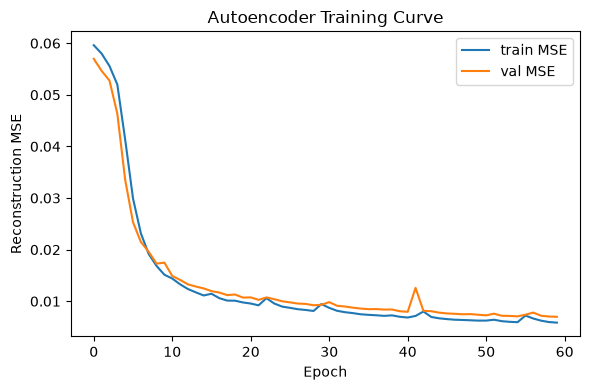

Final train MSE: 0.00586
Final val MSE:   0.00698


In [5]:
plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="train MSE")
plt.plot(history.history["val_loss"], label="val MSE")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("Autoencoder Training Curve")
plt.legend()
plt.tight_layout()
plt.savefig("training_curve.png", dpi=100)
plt.show()

print(f"Final train MSE: {history.history['loss'][-1]:.5f}")
print(f"Final val MSE:   {history.history['val_loss'][-1]:.5f}")


### Reconstructed examples

A quick visual sanity check before trusting any numeric reconstruction-error analysis: do the
reconstructions look like blurry versions of the originals, or like noise?


E0000 00:00:1795038912.836095 8698370 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


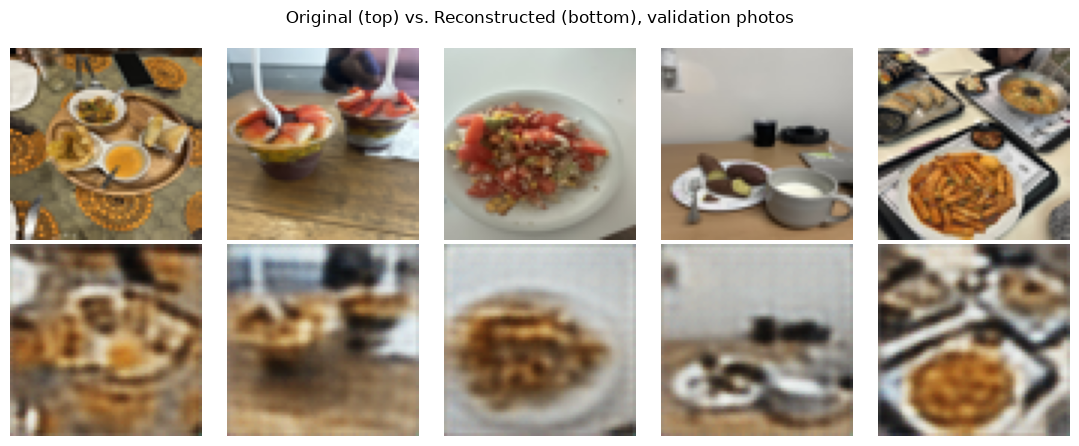

In [6]:
recon_val = autoencoder.predict(X_val, verbose=0)

n_show = 5
fig, axes = plt.subplots(2, n_show, figsize=(2.2 * n_show, 4.5))
for i in range(n_show):
    axes[0, i].imshow(X_val[i])
    axes[0, i].axis("off")
    axes[1, i].imshow(recon_val[i])
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("original", fontsize=10)
axes[1, 0].set_ylabel("reconstructed", fontsize=10)
plt.suptitle("Original (top) vs. Reconstructed (bottom), validation photos")
plt.tight_layout()
plt.savefig("reconstructions.png", dpi=100)
plt.show()


## Core Question 3d: Performance Measurement

Reconstruction error (per-photo MSE between original and reconstruction) is the natural
performance metric for an autoencoder, there are no ground-truth labels involved in training to
score against. Computed per-photo reconstruction error across **all 199 photos** (not just the
validation split), since the goal here isn't to prove the autoencoder generalizes, it's to look
at every photo's error and see what's high vs. low.


In [7]:
recon_all = autoencoder.predict(X, verbose=0)
mse_per_photo = ((X - recon_all) ** 2).mean(axis=(1, 2, 3))

results = usable.copy()
results["recon_mse"] = mse_per_photo
results["in_val_split"] = results.index.isin(val_idx)

print(results.groupby("label")["recon_mse"].agg(["mean", "std", "count"]))


              mean       std  count
label                              
allergen  0.005414  0.001646     52
safe      0.006218  0.002514    147


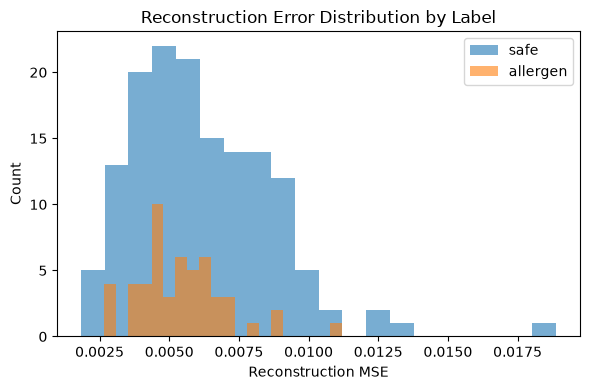

Welch's t-test, safe vs allergen reconstruction MSE: t=2.608, p=0.0101


In [8]:
plt.figure(figsize=(6, 4))
for label, color in [("safe", "tab:blue"), ("allergen", "tab:orange")]:
    subset = results[results["label"] == label]["recon_mse"]
    plt.hist(subset, bins=20, alpha=0.6, label=label, color=color)
plt.xlabel("Reconstruction MSE")
plt.ylabel("Count")
plt.title("Reconstruction Error Distribution by Label")
plt.legend()
plt.tight_layout()
plt.savefig("recon_error_by_label.png", dpi=100)
plt.show()

from scipy import stats
safe_mse = results[results["label"] == "safe"]["recon_mse"]
allergen_mse = results[results["label"] == "allergen"]["recon_mse"]
t_stat, p_val = stats.ttest_ind(safe_mse, allergen_mse, equal_var=False)
print(f"Welch's t-test, safe vs allergen reconstruction MSE: t={t_stat:.3f}, p={p_val:.4f}")


### Checking the Grad-CAM example photos specifically

Assignment 1's Grad-CAM analysis flagged three highest-confidence correct allergen predictions
as interesting cases: `IMG_5760.HEIC` (clean egg-detection, heatmap on the actual egg),
`IMG_8426.HEIC` (heatmap on a chicken dish, unverifiable), and `IMG_3679.HEIC` (the confound
case, heatmap on starchy chunks instead of the visible egg/beans). If reconstruction error
tracks visual unusualness in a way that's useful, these are worth checking directly rather than
only looking at label-level averages.


In [9]:
gradcam_examples = ["IMG_5760.HEIC", "IMG_8426.HEIC", "IMG_3679.HEIC"]
results_sorted = results.sort_values("recon_mse", ascending=False).reset_index(drop=True)
results_sorted["error_rank"] = results_sorted.index + 1
results_sorted["error_percentile"] = 100 * (1 - results_sorted["error_rank"] / len(results_sorted))

for fname in gradcam_examples:
    row = results_sorted[results_sorted["filename"] == fname]
    if len(row):
        r = row.iloc[0]
        print(f"{fname}: recon_mse={r['recon_mse']:.5f}, rank {int(r['error_rank'])}/{len(results_sorted)} "
              f"(top {100 - r['error_percentile']:.1f}% highest error), label={r['label']}")
    else:
        print(f"{fname}: not found in usable set")


IMG_5760.HEIC: recon_mse=0.00659, rank 64/199 (top 32.2% highest error), label=allergen
IMG_8426.HEIC: recon_mse=0.00454, rank 144/199 (top 72.4% highest error), label=allergen
IMG_3679.HEIC: recon_mse=0.00624, rank 76/199 (top 38.2% highest error), label=allergen


### Result and Discussion

Fill in after running: does `t-test p-value` suggest safe vs. allergen reconstruction error
differs at all (expected: probably not significantly, reconstruction error is about visual
*unusualness*, not allergen content specifically, these are different signals). Report where
the three Grad-CAM example photos land in the reconstruction-error ranking, a high rank for
`IMG_3679.HEIC` (the confound case) would be a genuinely interesting finding worth carrying into
Assignment 2, since it would mean the autoencoder is independently flagging the same photo that
tripped up Grad-CAM interpretability, via a completely different, unsupervised mechanism.

**Why this is useful for Assignment 2, independent of whether the correlation is strong**: the
bottleneck features (`encoder.predict(X)`, shape `(199, 8, 8, 64)` flattened) are also a third
feature representation to add to Assignment 1's existing two (hand-crafted features, raw/CNN
pixels), for a direct three-way representation comparison, exactly the kind of "comparison
condition" Assignment 2 asks for.


In [10]:
latent_features = encoder.predict(X, verbose=0).reshape(len(X), -1)
print(f"Flattened latent features shape: {latent_features.shape}")
np.save("autoencoder_latent_features.npy", latent_features)
print("Saved for reuse in Assignment 2.")


Flattened latent features shape: (199, 4096)
Saved for reuse in Assignment 2.


In [11]:
autoencoder.save("food_photo_autoencoder.keras")
print("Model saved: food_photo_autoencoder.keras")


Model saved: food_photo_autoencoder.keras
